<a href="https://colab.research.google.com/github/prahladsharma21178-glitch/Machin-_Learning-algorithms-and-practice-using-Python/blob/main/kmeanclustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [ ]:
df=pd.read_csv("https://raw.githubusercontent.com/gakudo-ai/open-datasets/refs/heads/main/Mall_Customers.csv")

In [ ]:
df
X=df[['Annual Income (k$)','Spending Score (1-100)']]
X

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
195,120,79
196,126,28
197,126,74
198,137,18


In [ ]:
scaled=StandardScaler()
x_scaled=scaled.fit_transform(X)
x_scaled

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

Text(0.5, 1.0, 'customer distribution')

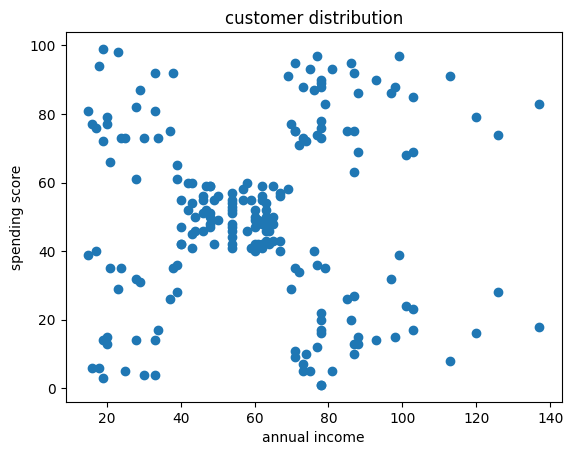

In [ ]:
plt.scatter(X['Annual Income (k$)'],X['Spending Score (1-100)'])
plt.xlabel('annual income')
plt.ylabel('spending score')
plt.title('customer distribution')

In [ ]:
wcss=[]
for i in range(1,11):
  k=KMeans(random_state=42,n_clusters=i,init='k-means++',n_init=10)
  k.fit(x_scaled)
  wcss.append(k.inertia_)

Text(0.5, 1.0, 'elbow method')

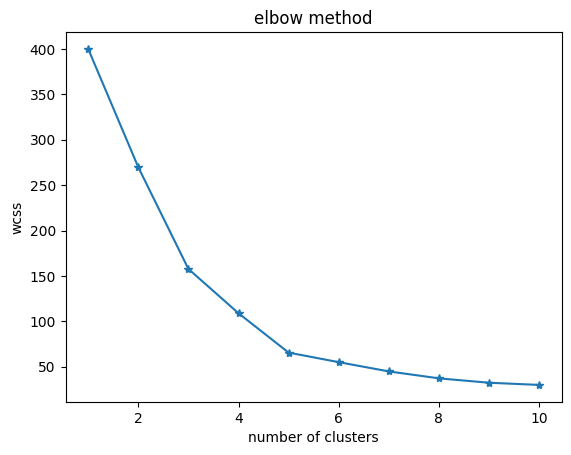

In [ ]:
from matplotlib import markers
plt.plot(range(1,11),wcss,marker='*')
plt.xlabel('number of clusters')
plt.ylabel('wcss')
plt.title('elbow method')


In [ ]:
model=KMeans(random_state=42,n_init=10,init='k-means++',n_clusters=6)
model.fit(x_scaled)

KMeans(n_clusters=6, n_init=10, random_state=42)

In [ ]:
predict=model.predict(x_scaled)
predict

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 0,
       3, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 1, 5, 0, 5, 1, 5, 1, 5,
       0, 5, 1, 5, 1, 5, 1, 5, 1, 5, 0, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5,
       1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5, 1, 5,
       1, 5, 1, 5, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2], dtype=int32)

Text(0.5, 1.0, 'customer distribution')

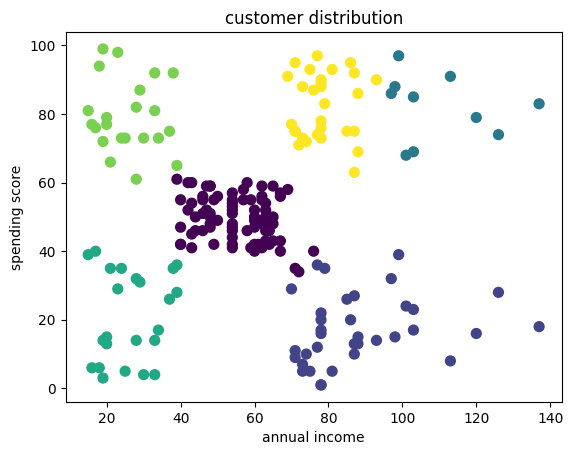

In [ ]:
plt.scatter(X['Annual Income (k$)'],X['Spending Score (1-100)'],cmap='viridis',s=50,c=predict)
plt.xlabel('annual income')
plt.ylabel('spending score')
plt.title('customer distribution')

In [ ]:
new=pd.DataFrame({'Annual Income (k$)':[95],'Spending Score (1-100)':[100]})
new_scale=scaled.transform(new)
p=model.predict(new_scale)
p

array([2], dtype=int32)